# SABR and SVI: calibrating a smile, and what arbitrage looks like

Checks on `pricing.sabr` and `pricing.svi`:

1. **Synthetic noisy smile**: generate quotes from a known SABR smile and add noise, so the right answer is known.
2. **SABR calibration** with $\beta$ fixed, and why $\beta$ cannot be calibrated from a single smile (collinearity with $\rho$).
3. **SVI calibration** of the same smile.
4. **Butterfly arbitrage**: an SVI slice that fits a shape but has $g(k)<0$, seen through $g(k)$ and through the implied density.
5. **Calendar arbitrage**: two slices whose total variance curves cross.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pricing.black_scholes import black_scholes_price
from pricing.sabr import SabrParams, calibrate_sabr, sabr_implied_vol
from pricing.svi import (SviParams, butterfly_g, calendar_violations, fit_svi,
                         has_butterfly_arbitrage, svi_total_variance)

In [2]:
# Forward-based set up: forward F, maturity T. With r = 0 the forward equals spot, so black_scholes_price(S=F, r=0) is the Black-76 price.
F = 100.0
T = 1.0
strikes = np.linspace(70, 140, 15)

true_sabr = SabrParams(alpha=2.0, beta=0.5, rho=-0.4, nu=0.6)
clean_vols = sabr_implied_vol(F, strikes, T, true_sabr)

rng = np.random.default_rng(11)
noise_sd = 0.002  # 0.2 vol points, roughly a bid-ask half-spread
market_vols = clean_vols + noise_sd * rng.standard_normal(strikes.size)

print(f"ATM vol (clean): {np.interp(F, strikes, clean_vols):.4f}")
print(f"RMS noise added: {np.sqrt(np.mean((market_vols - clean_vols)**2)):.4f}")

ATM vol (clean): 0.2034
RMS noise added: 0.0017


## 1. SABR calibration with beta fixed

$\beta$ is fixed at 0.5 (the value used to generate the data), and $(\alpha,\rho,\nu)$ are fitted. Then the same smile is fitted with other values of $\beta$ to see how much the data can tell them apart.

True   : SabrParams(alpha=2.0, beta=0.5, rho=-0.4, nu=0.6)
Fitted : SabrParams(alpha=2.000175930860415, beta=0.5, rho=-0.4017533771326541, nu=0.6080805680516853)


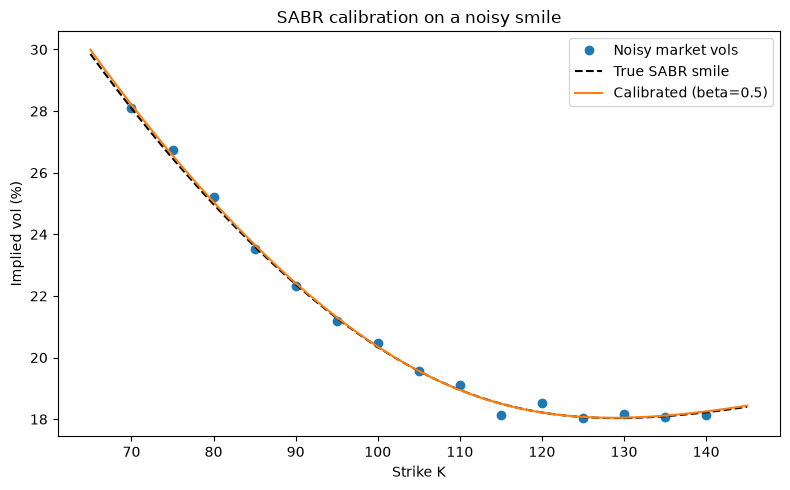

In [3]:
k_dense = np.linspace(65, 145, 200)

fit_true_beta = calibrate_sabr(F, strikes, market_vols, T, beta=0.5)
print("True   :", true_sabr)
print("Fitted :", fit_true_beta)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(strikes, 100 * market_vols, "o", label="Noisy market vols")
ax.plot(k_dense, 100 * sabr_implied_vol(F, k_dense, T, true_sabr), "k--", label="True SABR smile")
ax.plot(k_dense, 100 * sabr_implied_vol(F, k_dense, T, fit_true_beta), label="Calibrated (beta=0.5)")
ax.set_xlabel("Strike K")
ax.set_ylabel("Implied vol (%)")
ax.set_title("SABR calibration on a noisy smile")
ax.legend()
fig.tight_layout()
plt.show()

In [4]:
rows = []
fits = {}
for beta in (0.0, 0.25, 0.5, 0.75, 1.0):
    p = calibrate_sabr(F, strikes, market_vols, T, beta=beta)
    fits[beta] = p
    resid = sabr_implied_vol(F, strikes, T, p) - market_vols
    rows.append({"beta": beta, "alpha": p.alpha, "rho": p.rho, "nu": p.nu,
                 "rmse vs noisy quotes (vol pts)": 100 * np.sqrt(np.mean(resid**2)),
                 "max |fit_beta - fit_0.5| on grid (vol pts)": 100 * np.max(np.abs(
                     sabr_implied_vol(F, k_dense, T, p) - sabr_implied_vol(F, k_dense, T, fit_true_beta)))})
df_beta = pd.DataFrame(rows)
df_beta.round(4)

,beta,alpha,rho,nu,rmse vs noisy quotes (vol pts),max |fit_beta - fit_0.5| on grid (vol pts)
0,0.00,19.8252,-0.2292,0.5538,0.1690,0.2551
1,0.25,6.2916,-0.3203,0.5787,0.1648,0.1289
2,0.50,2.0002,-0.4018,0.6081,0.1673,0.0000
3,0.75,0.6371,-0.4736,0.6416,0.1766,0.1316
4,1.00,0.2033,-0.5362,0.6789,0.1920,0.2655


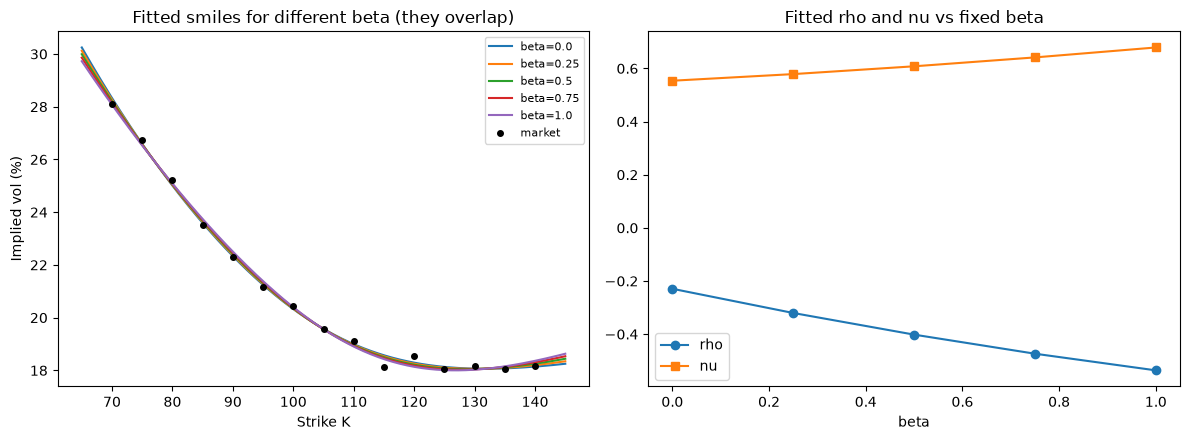

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for beta, p in fits.items():
    axes[0].plot(k_dense, 100 * sabr_implied_vol(F, k_dense, T, p), label=f"beta={beta}")
axes[0].plot(strikes, 100 * market_vols, "ko", markersize=4, label="market")
axes[0].set_title("Fitted smiles for different beta (they overlap)")
axes[0].set_xlabel("Strike K"); axes[0].set_ylabel("Implied vol (%)"); axes[0].legend(fontsize=8)

axes[1].plot(df_beta["beta"], df_beta["rho"], "o-", label="rho")
axes[1].plot(df_beta["beta"], df_beta["nu"], "s-", label="nu")
axes[1].set_title("Fitted rho and nu vs fixed beta")
axes[1].set_xlabel("beta"); axes[1].legend()
fig.tight_layout()
plt.show()

**Reading the beta table**

With $\beta=0.5$ the fit recovers the generating parameters ($\alpha=2.0002$, $\rho=-0.402$, $\nu=0.608$ vs. true 2.0, $-0.4$, 0.6). But $\beta=0$ fits the same noisy quotes with an RMSE of 0.169 vol points, essentially the same as the true $\beta$ (0.167) and better than $\beta=1$ (0.192). The fitted curves differ from the $\beta=0.5$ one by at most 0.13 to 0.27 vol points, which is the size of the noise. So the data cannot pick $\beta$.

What changes is the parameters: $\rho$ moves from $-0.23$ ($\beta=0$) to $-0.54$ ($\beta=1$) and $\nu$ from 0.55 to 0.68. Lower $\beta$ puts skew into the backbone of the model (CEV-like, vol rises when spot falls), so less correlation is needed; higher $\beta$ must get the same skew from $\rho$. $\alpha$ changes by two orders of magnitude only because it has units of $F^{1-\beta}$ ($\alpha\approx\sigma_{ATM}F^{1-\beta}$). The practical consequence: $\beta$ is fixed by convention or from history, and $\rho$ and $\nu$ must be read together with it. Deltas computed with different $\beta$ differ even if the smiles match.

## 2. SVI calibration of the same smile

SVI works in total variance $w=\sigma^2T$ against log-moneyness $k=\ln(K/F)$.

SviParams(a=np.float64(0.015122682373719202), b=np.float64(0.0865081091188633), rho=np.float64(-0.656647992943696), m=np.float64(0.04262257808087271), s=np.float64(0.26964482028130643))
butterfly arbitrage on fitted slice: False
RMSE SVI : 0.1593 vol pts
RMSE SABR: 0.1673 vol pts
RMS of the noise actually added (a fit below this is fitting noise): 0.1741 vol pts


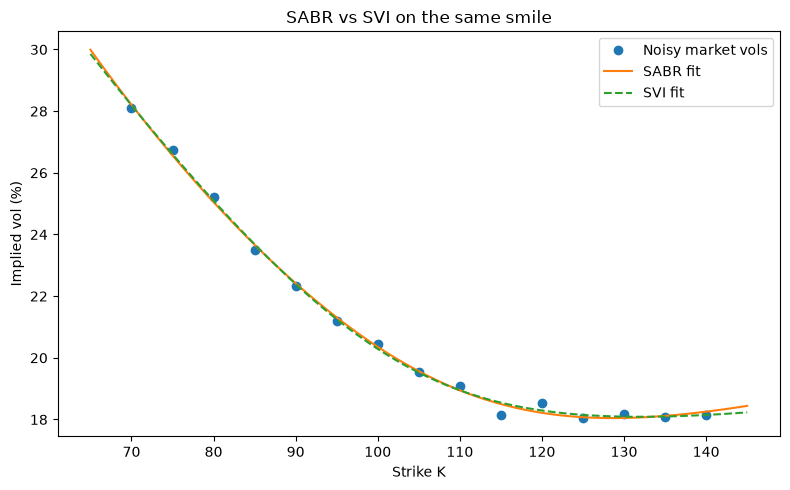

In [6]:
k_mkt = np.log(strikes / F)
w_mkt = market_vols**2 * T
svi_fit = fit_svi(k_mkt, w_mkt)
print(svi_fit)
print("butterfly arbitrage on fitted slice:", has_butterfly_arbitrage(svi_fit))

k_d = np.log(k_dense / F)
svi_vols = np.sqrt(svi_total_variance(k_d, svi_fit) / T)
resid_svi = np.sqrt(svi_total_variance(k_mkt, svi_fit) / T) - market_vols
resid_sabr = sabr_implied_vol(F, strikes, T, fit_true_beta) - market_vols
print(f"RMSE SVI : {100*np.sqrt(np.mean(resid_svi**2)):.4f} vol pts")
print(f"RMSE SABR: {100*np.sqrt(np.mean(resid_sabr**2)):.4f} vol pts")
print(f"RMS of the noise actually added (a fit below this is fitting noise): {100*np.sqrt(np.mean((market_vols - clean_vols)**2)):.4f} vol pts")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(strikes, 100 * market_vols, "o", label="Noisy market vols")
ax.plot(k_dense, 100 * sabr_implied_vol(F, k_dense, T, fit_true_beta), label="SABR fit")
ax.plot(k_dense, 100 * svi_vols, "--", label="SVI fit")
ax.set_xlabel("Strike K"); ax.set_ylabel("Implied vol (%)")
ax.set_title("SABR vs SVI on the same smile")
ax.legend()
fig.tight_layout()
plt.show()

**SABR vs SVI**

Both fit to within the noise: SVI RMSE 0.159 and SABR 0.167 vol points against 0.174 of noise actually added. SVI has five parameters and SABR three, so SVI having the smaller residual is expected and is not evidence that it is better; with this much noise a fit *below* the noise level just means some of it is being absorbed. The fitted SVI slice passes the butterfly check. The point of SVI is not fit quality but that its no-arbitrage conditions are explicit (next sections), which Hagan's SABR expansion does not give you.

## 3. Butterfly arbitrage

A slice is arbitrage-free in strike iff the risk-neutral density is non-negative. For SVI this is $g(k)\ge 0$. Below, an SVI slice that looks like a plausible equity smile with a tight kink near the minimum ($s=0.05$, $\rho=-0.9$) but has $g<0$ there. The implied density is obtained independently from the prices: $q(K)=\partial^2 C/\partial K^2$ (here $r=0$), by finite differences, so it doesn't rely on $g$.

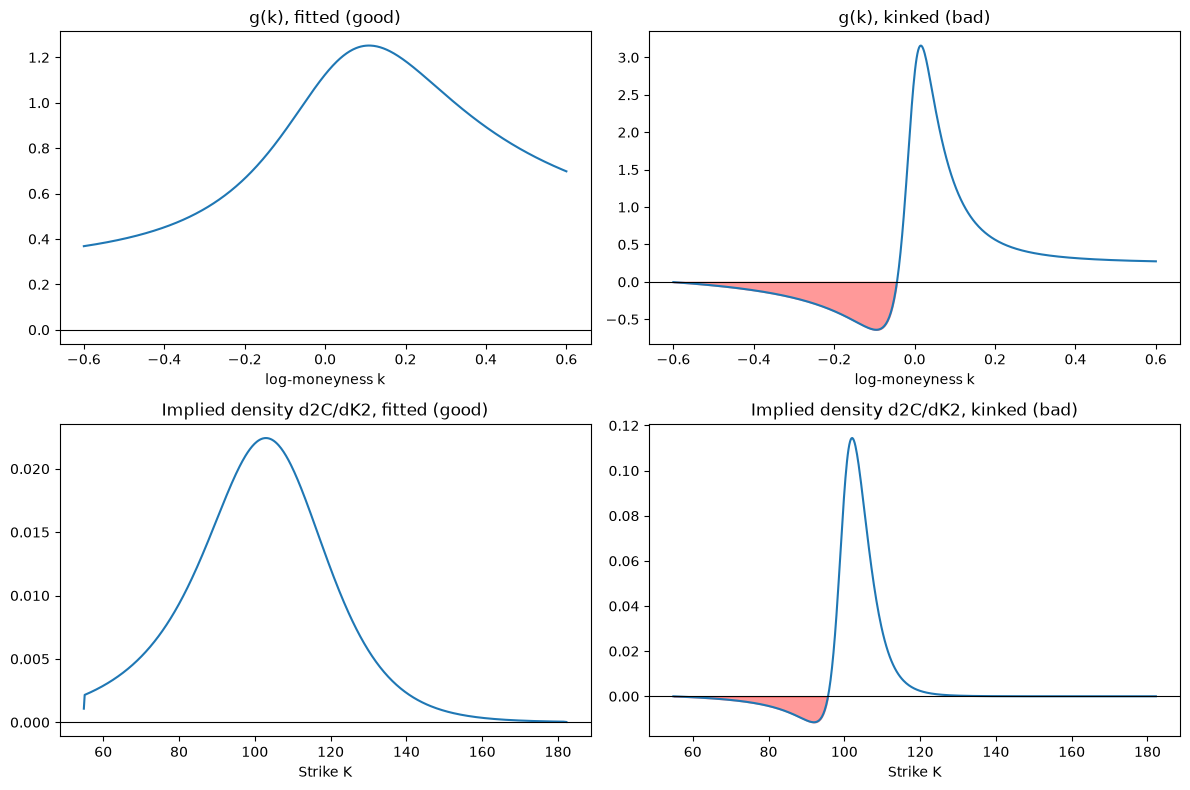

g(k) min  good / bad: 0.3683 -0.6398
density min good / bad: 2.3e-05 -0.011521
has_butterfly_arbitrage good / bad: False True


In [7]:
bad = SviParams(a=0.0, b=0.3, rho=-0.9, m=0.0, s=0.05)
good = svi_fit

k_g = np.linspace(-0.6, 0.6, 600)
K_g = F * np.exp(k_g)

def density_from_svi(p):
    vols = np.sqrt(svi_total_variance(k_g, p) / T)
    calls = np.array([black_scholes_price(F, K, T, 0.0, v, "call", 0.0) for K, v in zip(K_g, vols)])
    d1 = np.gradient(calls, K_g)
    return np.gradient(d1, K_g)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, (label, p) in enumerate([("fitted (good)", good), ("kinked (bad)", bad)]):
    axes[0, col].plot(k_g, butterfly_g(k_g, p))
    axes[0, col].axhline(0, color="k", linewidth=0.8)
    axes[0, col].fill_between(k_g, butterfly_g(k_g, p), 0, where=butterfly_g(k_g, p) < 0, color="red", alpha=0.4)
    axes[0, col].set_title(f"g(k), {label}")
    axes[0, col].set_xlabel("log-moneyness k")
    dens = density_from_svi(p)
    axes[1, col].plot(K_g, dens)
    axes[1, col].axhline(0, color="k", linewidth=0.8)
    axes[1, col].fill_between(K_g, dens, 0, where=dens < 0, color="red", alpha=0.4)
    axes[1, col].set_title(f"Implied density d2C/dK2, {label}")
    axes[1, col].set_xlabel("Strike K")
fig.tight_layout()
plt.show()

print("g(k) min  good / bad:", butterfly_g(k_g, good).min().round(4), butterfly_g(k_g, bad).min().round(4))
print("density min good / bad:", density_from_svi(good).min().round(6), density_from_svi(bad).min().round(6))
print("has_butterfly_arbitrage good / bad:", has_butterfly_arbitrage(good), has_butterfly_arbitrage(bad))

**Butterfly**

The kinked slice has $g_{min}=-0.64$ around $k\approx-0.1$ and the density computed from option prices, with no reference to $g$, is also negative there (minimum $-0.0115$), while the fitted slice has $g>0$ everywhere and a density that stays positive on this grid (minimum $2.3\times10^{-5}$). Negative density means a tight butterfly (long K-h, short 2K, long K+h) has negative price while paying off at least zero: free money. Note that the bad slice looks harmless as a plot of vol against strike; the arbitrage lives in the second derivative.

## 4. Calendar arbitrage

For a fixed log-moneyness, total variance must not decrease with maturity (otherwise a calendar spread has negative cost and non-negative payoff). Two slices that each look fine on their own can still cross each other.

butterfly arbitrage short / long: False False
calendar violations: [(0.5, 1.0)]


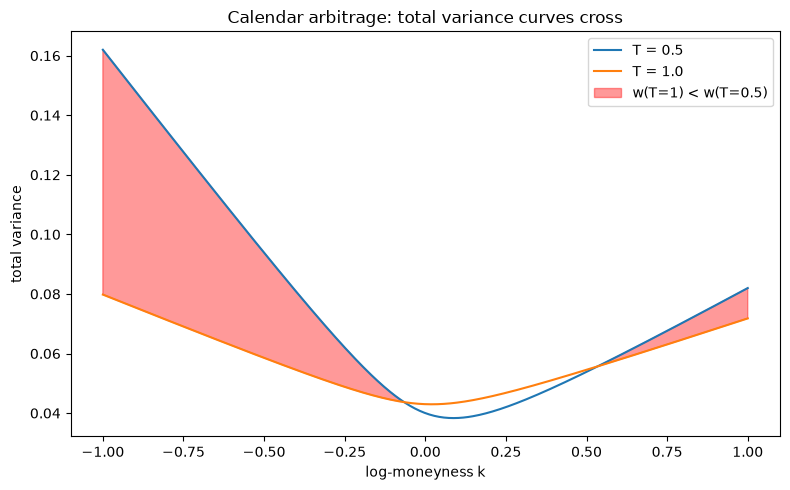

ATM (k=0): w(T=0.5) = 0.0400, w(T=1.0) = 0.0430
violated for k < -0.07 and for k > 0.54
K=  36.79: C(T=0.5) = 63.2625, C(T=1.0) = 63.2129, difference = -0.0496
K= 271.83: C(T=0.5) = 0.0028, C(T=1.0) = 0.0010, difference = -0.0018


In [8]:
s_short = SviParams(a=0.02, b=0.10, rho=-0.4, m=0.0, s=0.2)    # T = 0.5
s_long = SviParams(a=0.035, b=0.04, rho=-0.1, m=0.0, s=0.2)     # T = 1.0
slices = [(0.5, s_short), (1.0, s_long)]
print("butterfly arbitrage short / long:", has_butterfly_arbitrage(s_short), has_butterfly_arbitrage(s_long))
print("calendar violations:", calendar_violations(slices))

k_c = np.linspace(-1, 1, 400)
w1 = svi_total_variance(k_c, s_short)
w2 = svi_total_variance(k_c, s_long)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_c, w1, label="T = 0.5")
ax.plot(k_c, w2, label="T = 1.0")
ax.fill_between(k_c, w1, w2, where=w2 < w1, color="red", alpha=0.4, label="w(T=1) < w(T=0.5)")
ax.set_xlabel("log-moneyness k"); ax.set_ylabel("total variance")
ax.set_title("Calendar arbitrage: total variance curves cross")
ax.legend()
fig.tight_layout()
plt.show()

viol = w2 < w1
bad_k = k_c[viol]
print(f"ATM (k=0): w(T=0.5) = {svi_total_variance(0.0, s_short):.4f}, w(T=1.0) = {svi_total_variance(0.0, s_long):.4f}")
print(f"violated for k < {bad_k[bad_k < 0].max():.2f} and for k > {bad_k[bad_k > 0].min():.2f}")

# The trade-level meaning: a call at the longer maturity cheaper than the same-strike call at the shorter one.
for kk in (bad_k[bad_k < 0].min(), bad_k[bad_k > 0].max()):
    K_c = F * np.exp(kk)
    c1 = black_scholes_price(F, K_c, 0.5, 0.0, np.sqrt(svi_total_variance(kk, s_short) / 0.5), "call", 0.0)
    c2 = black_scholes_price(F, K_c, 1.0, 0.0, np.sqrt(svi_total_variance(kk, s_long) / 1.0), "call", 0.0)
    print(f"K={K_c:7.2f}: C(T=0.5) = {c1:.4f}, C(T=1.0) = {c2:.4f}, difference = {c2 - c1:+.4f}")

**Calendar**

The two slices pass the butterfly check individually. The long slice has higher total variance at the money (0.043 vs 0.040) but much flatter wings, so it ends up below the short one for $k<-0.07$ and $k>0.54$. At the violating strikes the call with longer maturity is cheaper than the same-strike call with shorter maturity (differences of $-0.05$ and $-0.002$), which cannot happen for a martingale forward: the longer call dominates the shorter one. Calibrating each expiry independently, as is done here, gives no protection against this; surface fitting has to impose it jointly (that is what the `vol-surface-risk` project has to deal with).